# Week 7 · Task D — The one screen
One figure, **5 panels**, 300 dpi, for the three readers: the Secretary (top-left only), the finance director (screenshots one panel), the journalist (sent the link).

**Reading order, in one sentence:** the headline number (①) and, beside it, whether it is real (②), then why (③), then the money (④), then where to act (⑤).

| # | Panel | Answers | Reader |
|---|---|---|---|
| ① | KPI tile: network on-time **and** what happened to every mode | "Is service better?" | Secretary — this tile alone must not mislead |
| ② | **Is it real?** on-time by mode, 2025 Q2 → 2026 Q2 | the reversal | everyone |
| ③ | **Why** — share of departures by mode (the mix) | the cause | journalist |
| ④ | Fare box — revenue per journey, mix vs fares | "Is the fare box recovering?" | finance director |
| ⑤ | Map — boardings per 1,000 residents | "Where should the next corridor go?" | board |

The mix is **computed**, not asserted: `dashlib.rate_decomposition()` (exact: within + mix = change).

In [1]:
import sys, os
from pathlib import Path
def _find_root():
    here = Path.cwd()
    for p in [here, here / "week7" / "assignments", here.parent / "assignments"]:
        if (p / "dashlib.py").exists() and (p / "data" / "ridership_daily.csv").exists():
            return p
    raise FileNotFoundError("Put this notebook in week7/assignments/ (next to dashlib.py) and run it from there.")
ROOT = _find_root(); os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("working in", ROOT)

working in c:\Users\Nas Graphy\Downloads\Data-Visualization\Week 7


In [2]:
import numpy as np, pandas as pd, textwrap
import matplotlib; import matplotlib.pyplot as plt
import vizlib, tslib, geolib, dashlib
from vizlib import PALETTE
vizlib.style_defaults()
pd.set_option("display.width", 200)
CLEAN = Path("clean")
need = ["district_transit_clean.csv", "routes_clean.csv", "ridership_calendar.csv", "fare_revenue_clean.csv"]
assert all((CLEAN / f).exists() for f in need), "Run partA_process.ipynb first: it writes clean/"

reg = pd.read_csv(CLEAN / "district_transit_clean.csv")
rt = pd.read_csv(CLEAN / "routes_clean.csv")
cal = pd.read_csv(CLEAN / "ridership_calendar.csv", parse_dates=["date"])
fr = pd.read_csv(CLEAN / "fare_revenue_clean.csv")
feats = geolib.read_geojson("data/regions.geojson")
parts = fr[~fr.is_total]                                  # the 216 real parts; the 72 subtotals are out
COMPLETE_END = "2026-08-31"                               # 2026-09 is a partial month (Bus, Ferry stopped filing 22 Sep)
MODES = ["Metro", "BRT", "Bus", "Ferry"]
# one hue per mode, everywhere. Ferry's 4th hue is below 3:1 contrast on white, so every mode is ALSO direct-labelled.
MODE_COL = {"Metro": PALETTE["series"][0], "BRT": PALETTE["series"][2], "Bus": PALETTE["series"][1], "Ferry": PALETTE["series_4th"]}
filed = cal[cal.status == "filed"]

def wrap(s, n=160): return "\n".join(textwrap.wrap(s, n))
def frame(fig, title, caption, top=0.84):
    """Finding as the title, the decision it supports as a one-line caption."""
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
    fig.text(0.01, 0.995 - 0.075 * (6.0 / fig.get_size_inches()[1]), caption, ha="left", va="top", fontsize=9.5, style="italic", color=PALETTE["ink_soft"])
    fig.subplots_adjust(top=top)

In [3]:
Q = lambda a, b: filed[(filed.date >= a) & (filed.date <= b)]
before, after = Q("2025-04-01", "2025-06-30"), Q("2026-04-01", "2026-06-30")        # the two complete quarters, declared on the figure
dec = dashlib.rate_decomposition(before, after, "mode", "trips_on_time", "trips_operated")
g = dec["groups"].loc[MODES]
print(f"network on-time {dec['rate_before']:.2f}% -> {dec['rate_after']:.2f}% ({dec['change']:+.2f} pts) | within {dec['within']:+.2f} | mix {dec['mix']:+.2f} | reversal={dec['reversal']}")
print(g.round(2).to_string())
assert dec["reversal"] and abs(dec["within"] + dec["mix"] - dec["change"]) < 1e-9
assert round(dec["rate_before"], 2) == 78.87 and round(dec["rate_after"], 2) == 80.60 and round(dec["within"], 2) == -1.10 and round(dec["mix"], 2) == 2.82
# robustness: the reversal must not be an artefact of the window I picked
for name, (a0, a1, b0, b1) in {"first 3 vs last 3 complete months": ("2025-04-01", "2025-06-30", "2026-06-01", "2026-08-31"),
                               "first 6 vs last 6": ("2025-04-01", "2025-09-30", "2026-03-01", "2026-08-31")}.items():
    d2 = dashlib.rate_decomposition(Q(a0, a1), Q(b0, b1), "mode", "trips_on_time", "trips_operated")
    print(f"  window '{name}': {d2['change']:+.2f} pts, all modes down = {d2['reversal']}")

bus_dep = (after[after['mode']=='Bus'].trips_operated.sum() / before[before['mode']=='Bus'].trips_operated.sum() - 1) * 100
print(f'Bus departures operated, 2025 Q2 -> 2026 Q2: {bus_dep:+.0f}%')

# the fare box: revenue per journey, mix vs fares (same exact decomposition, per=1 -> PKR)
pm = parts[parts.complete_month]; f0, f1 = pm[pm.month == "2025-04"], pm[pm.month == "2026-08"]
fd = dashlib.rate_decomposition(f0, f1, "mode", "revenue_pkr", "trips", per=1.0)
j_chg, r_chg = (f1.trips.sum() / f0.trips.sum() - 1) * 100, (f1.revenue_pkr.sum() / f0.revenue_pkr.sum() - 1) * 100
print(f"journeys {j_chg:+.1f}%, revenue {r_chg:+.1f}% | revenue per journey {fd['rate_before']:.2f} -> {fd['rate_after']:.2f} PKR (+{fd['change']:.2f}): within-mode fares {fd['within']:+.2f}, mix {fd['mix']:+.2f} ({fd['mix']/fd['change']*100:.0f}% of the rise)")

# the map
rate = reg.set_index("code").boardings_annual / reg.set_index("code").population * 1000
top3 = rate.sort_values(ascending=False).head(3)
# monthly network on-time for the tile's sparkline (sum, then divide)
mo = filed[filed.date <= COMPLETE_END].assign(m=lambda d: d.date.dt.to_period("M")).groupby("m")[["trips_on_time", "trips_operated"]].sum()
spark = (mo.trips_on_time / mo.trips_operated * 100)

network on-time 78.87% -> 80.60% (+1.73 pts) | within -1.10 | mix +2.82 | reversal=True
       rate_before  rate_after  delta  share_before  share_after  share_delta
mode                                                                         
Metro        96.11       94.80  -1.31         10.90        21.81        10.91
BRT          88.09       87.24  -0.85         15.09        18.35         3.26
Bus          74.24       73.14  -1.10         71.64        57.61       -14.03
Ferry        80.97       79.78  -1.19          2.37         2.23        -0.14
  window 'first 3 vs last 3 complete months': +2.02 pts, all modes down = True
  window 'first 6 vs last 6': +1.52 pts, all modes down = True
Bus departures operated, 2025 Q2 -> 2026 Q2: -24%
journeys +12.1%, revenue +26.9% | revenue per journey 36.52 -> 41.32 PKR (+4.80): within-mode fares +0.24, mix +4.56 (95% of the rise)


## The channel plan — checked before anything is drawn

In [4]:
PLAN = [
    {"panel": "1 kpi",  "x": "month (sparkline)", "y": "network on-time %"},
    {"panel": "2 real", "x": "period", "y": "on-time %", "hue": "mode", "shape": "period"},
    {"panel": "3 mix",  "x": "share of departures %", "y": "mode", "hue": "mode", "shape": "period"},
    {"panel": "4 fare", "x": "change in PKR per journey", "y": "component"},
    {"panel": "5 map",  "lightness": "boardings per 1,000 residents"},
]
cc = dashlib.channel_conflicts(PLAN)
print("channel_conflicts ok:", cc["ok"], "| conflicts:", cc["conflicts"]); print("redundant coding (deliberate):", cc["redundant"]); print("positional (reported, not flagged):", cc["positional"])
assert cc["ok"]
CH_TEXT = {"hue": "mode (Metro blue, BRT green, Bus orange, Ferry pink) - nothing else uses hue; the kpi delta and the map are deliberately NOT coloured",
           "shape": "period (hollow = 2025 Q2, filled = 2026 Q2) in panels 2 and 3 - one meaning", "lightness": "boardings per 1,000 residents, panel 5 only (a grey ramp, so it cannot be read as a mode)"}
import io, contextlib, matplotlib.ticker
hexes = [MODE_COL[m] for m in MODES]; buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    for kind in ("deutan", "protan", "tritan"): vizlib.cvd_report(hexes, kind)
print(buf.getvalue())
worst = {k: vizlib.worst_pair(hexes, k) for k in ("normal", "deutan", "protan", "tritan")}
for k, w in worst.items(): print(f"worst pair under {k:7s}: {w[2]} vs {w[3]}  dE {w[4]:.1f}  -> {vizlib.verdict(w[4])}")
print("=> a pair under 8 is legal only with a second channel: every mode is ALSO direct-labelled (and the y-position in panel 3), so identity is never colour alone.")

channel_conflicts ok: True | conflicts: {}
redundant coding (deliberate): {'period': ['x', 'shape'], 'mode': ['y', 'hue']}
positional (reported, not flagged): {'x': ['month (sparkline)', 'period', 'share of departures %', 'change in PKR per journey'], 'y': ['network on-time %', 'on-time %', 'mode', 'component']}
deutan simulation
  #0072B2  ->  #3B67B1
  #009E73  ->  #8A8676
  #D55E00  ->  #9E8C00
  #CC79A7  ->  #9498A5
protan simulation
  #0072B2  ->  #5375B5
  #009E73  ->  #9A9271
  #D55E00  ->  #817100
  #CC79A7  ->  #808BA9
tritan simulation
  #0072B2  ->  #008289
  #009E73  ->  #009E92
  #D55E00  ->  #EB4050
  #CC79A7  ->  #D6788A

worst pair under normal : #D55E00 vs #CC79A7  dE 16.4  -> clear
worst pair under deutan : #009E73 vs #CC79A7  dE 7.5  -> needs a second channel
worst pair under protan : #0072B2 vs #CC79A7  dE 9.5  -> ok
worst pair under tritan : #0072B2 vs #009E73  dE 8.4  -> ok
=> a pair under 8 is legal only with a second channel: every mode is ALSO direct-labelled (

## The screen

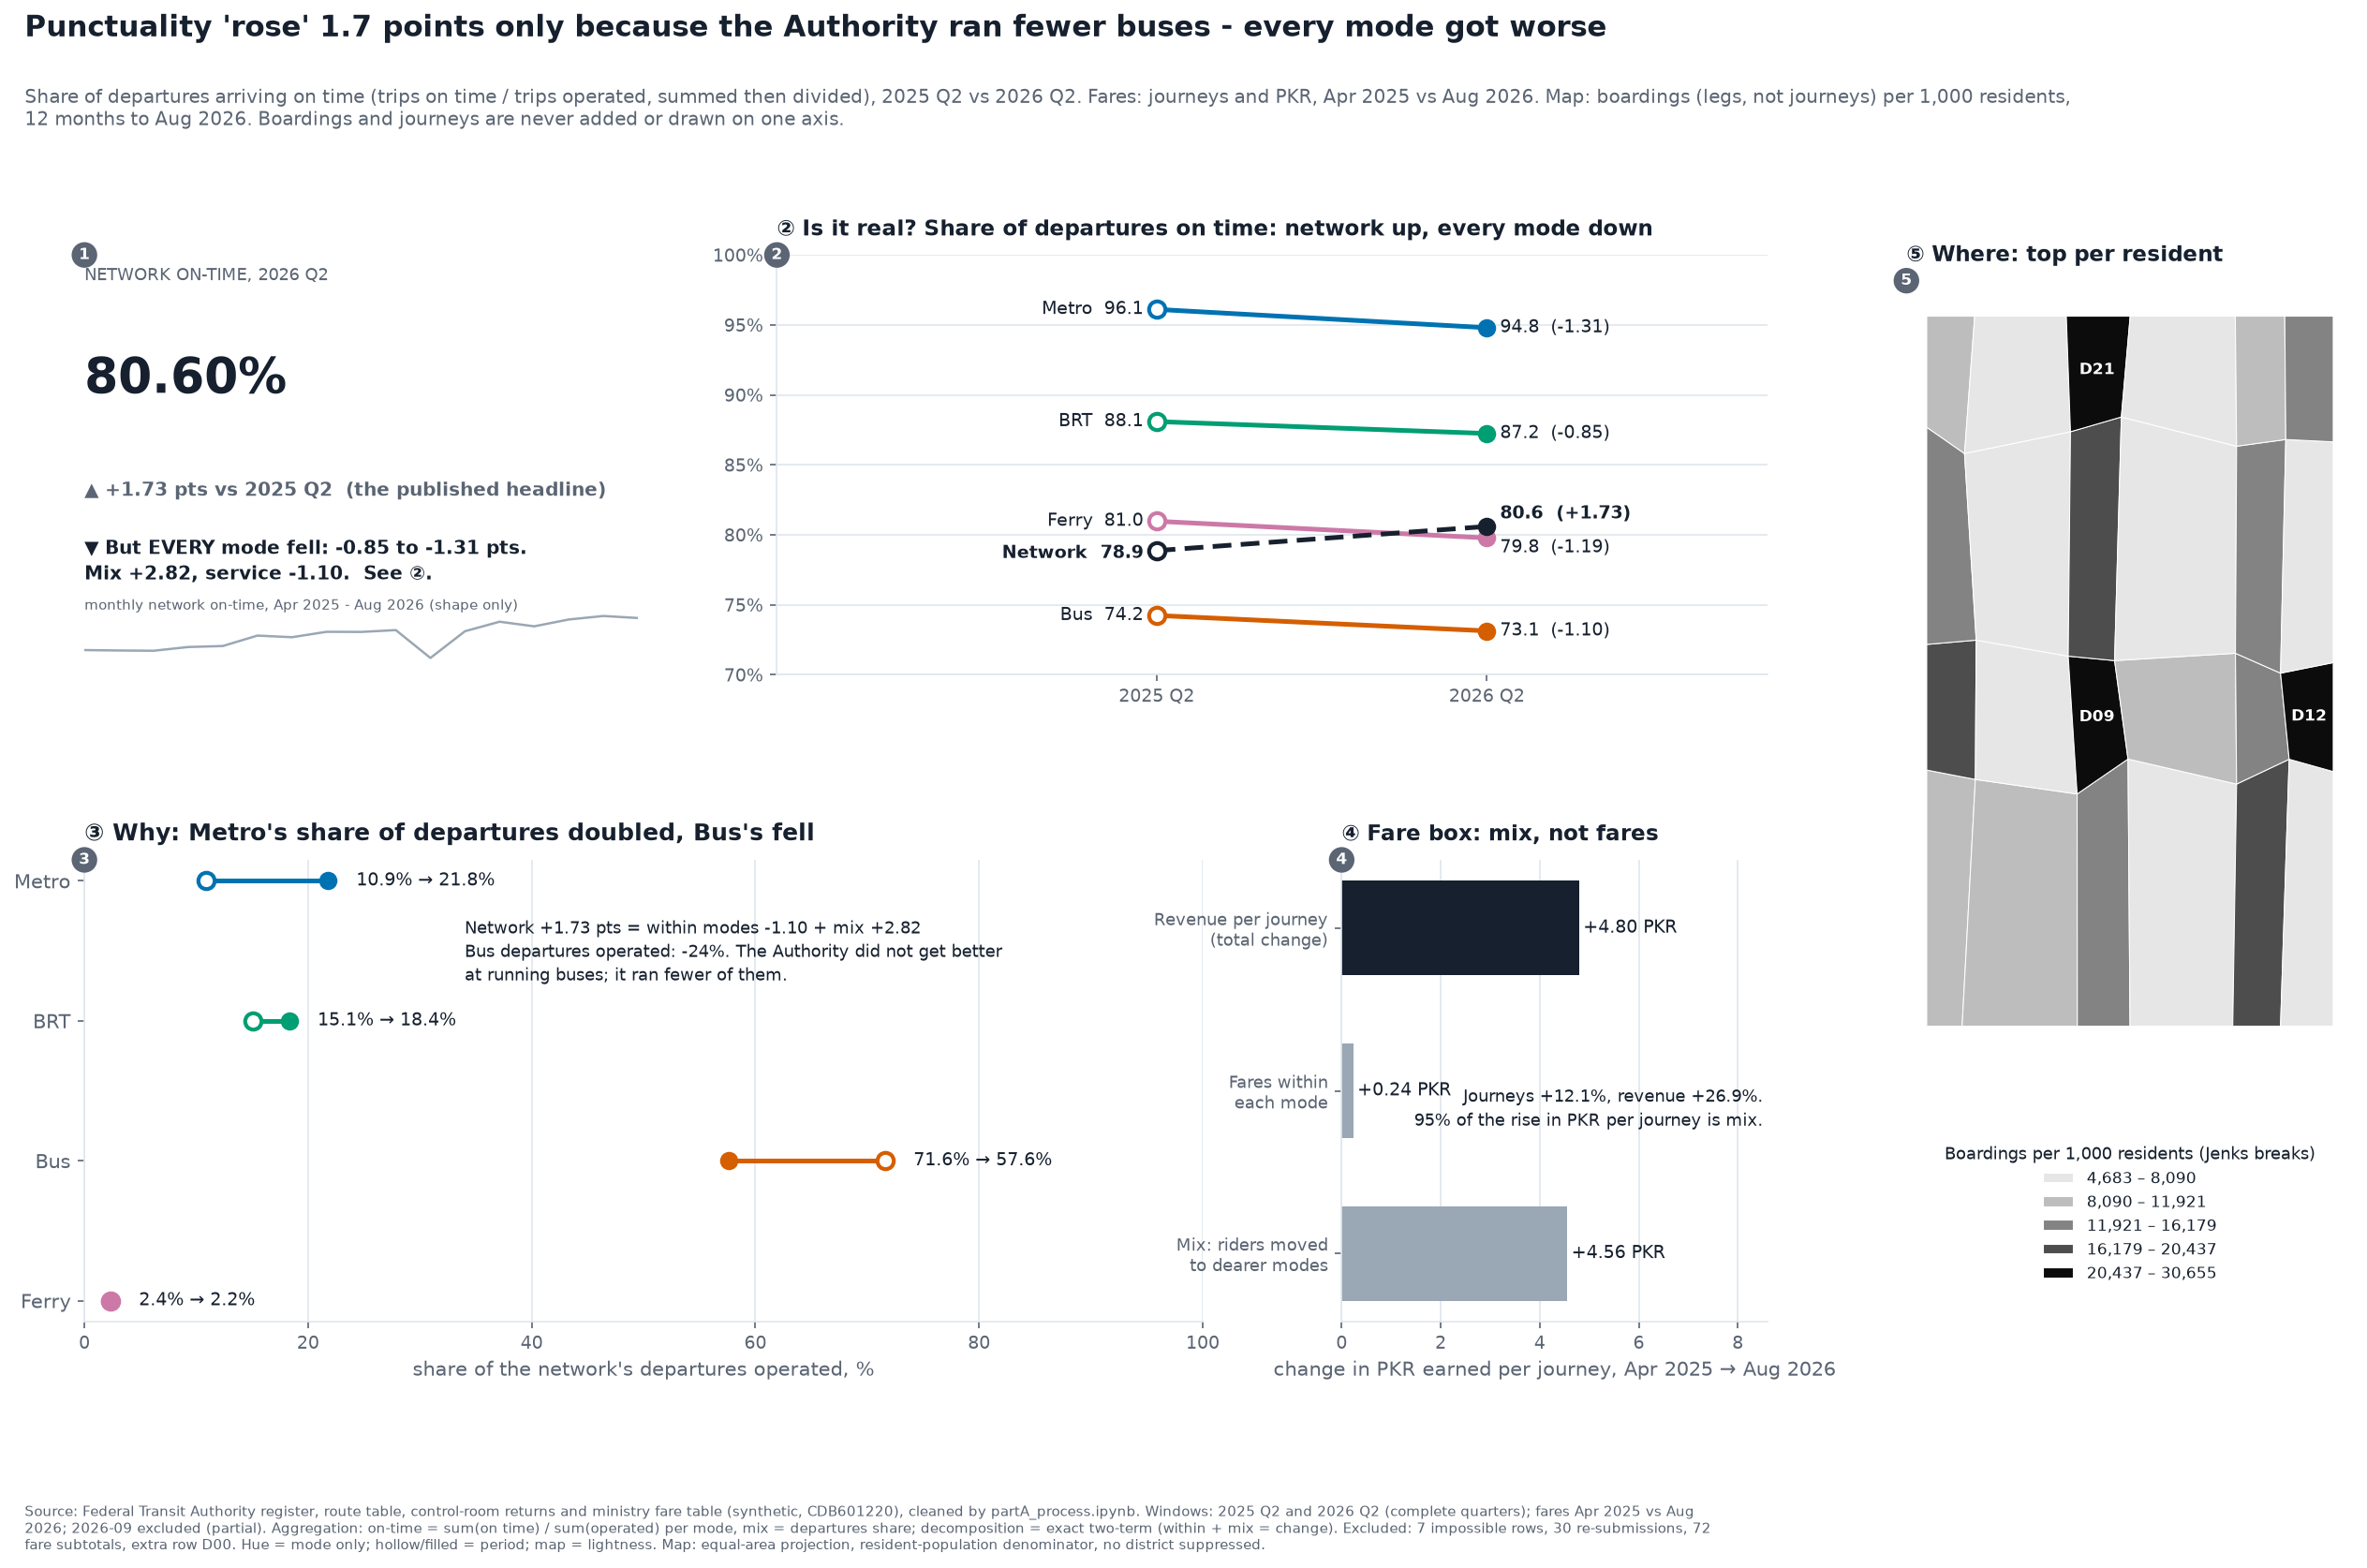

In [5]:
fig = plt.figure(figsize=(17, 10.4))
axd = dashboard_grid = dashlib.dashboard_grid(
    fig, [["kpi", "real", "real", "map"], ["mix", "mix", "fare", "map"]],
    headline=f"Punctuality 'rose' {dec['change']:.1f} points only because the Authority ran fewer buses - every mode got worse",
    standfirst=("Share of departures arriving on time (trips on time / trips operated, summed then divided), 2025 Q2 vs 2026 Q2. Fares: journeys and PKR, Apr 2025 vs Aug 2026. "
                "Map: boardings (legs, not journeys) per 1,000 residents,\n12 months to Aug 2026. Boardings and journeys are never added or drawn on one axis."),
    order=["kpi", "real", "mix", "fare", "map"], height_ratios=[1.0, 1.1], width_ratios=[1.3, 1, 1, 1.05], hspace=0.42, wspace=0.30, top=0.82)
fig.subplots_adjust(left=0.035, right=0.985, bottom=0.09)
INK, SOFT = PALETTE["ink"], PALETTE["ink_soft"]

# ---- 1 kpi: the headline number AND whether it is real, in one tile
a = axd["kpi"]
dashlib.kpi_tile(a, "Network on-time, 2026 Q2", dec["rate_after"], fmt="{:.2f}%", series=spark.values)
a.text(0.0, 0.18, "monthly network on-time, Apr 2025 - Aug 2026 (shape only)", fontsize=7, color=SOFT, va="top")
a.text(0.0, 0.46, f"\u25B2 {dec['change']:+.2f} pts vs 2025 Q2  (the published headline)", fontsize=9.5, fontweight="bold", color=SOFT, va="top")
a.text(0.0, 0.33, f"\u25BC But EVERY mode fell: {g.delta.max():+.2f} to {g.delta.min():+.2f} pts.\nMix {dec['mix']:+.2f}, service {dec['within']:+.2f}.  See \u2461.", fontsize=9.5, fontweight="bold", color=INK, va="top", linespacing=1.35)

# ---- 2 real: slope chart, network vs each mode
a = axd["real"]; ypos = {}
for mo_ in MODES:
    r0, r1 = g.loc[mo_, "rate_before"], g.loc[mo_, "rate_after"]
    a.plot([0, 1], [r0, r1], color=MODE_COL[mo_], lw=2.4, zorder=3)
    a.scatter([0], [r0], s=70, facecolor="white", edgecolor=MODE_COL[mo_], lw=2, zorder=4); a.scatter([1], [r1], s=70, color=MODE_COL[mo_], zorder=4)
    a.text(-0.04, r0, f"{mo_}  {r0:.1f}", ha="right", va="center", fontsize=9, color=INK); a.text(1.04, r1 + (-0.7 if mo_ == "Ferry" else 0), f"{r1:.1f}  ({g.loc[mo_, 'delta']:+.2f})", ha="left", va="center", fontsize=9, color=INK)
a.plot([0, 1], [dec["rate_before"], dec["rate_after"]], color=INK, lw=2.4, ls=(0, (4, 2)), zorder=3)
a.scatter([0], [dec["rate_before"]], s=70, facecolor="white", edgecolor=INK, lw=2, zorder=4); a.scatter([1], [dec["rate_after"]], s=70, color=INK, zorder=4)
a.text(-0.04, dec["rate_before"] - 0.2, f"Network  {dec['rate_before']:.1f}", ha="right", va="center", fontsize=9, fontweight="bold", color=INK)
a.text(1.04, dec["rate_after"] + 0.9, f"{dec['rate_after']:.1f}  ({dec['change']:+.2f})", ha="left", va="center", fontsize=9, fontweight="bold", color=INK)
a.set_xlim(-1.15, 1.85); a.set_ylim(70, 100); a.set_xticks([0, 1]); a.set_xticklabels(["2025 Q2", "2026 Q2"]); a.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%d%%")); a.grid(axis="x", visible=False)
a.set_title("\u2461 Is it real? Share of departures on time: network up, every mode down", fontsize=11)

# ---- 3 mix: where the departures went
a = axd["mix"]
for i, mo_ in enumerate(MODES[::-1]):
    s0, s1 = g.loc[mo_, "share_before"], g.loc[mo_, "share_after"]
    a.plot([s0, s1], [i, i], color=MODE_COL[mo_], lw=2.4, zorder=3)
    a.scatter([s0], [i], s=70, facecolor="white", edgecolor=MODE_COL[mo_], lw=2, zorder=4); a.scatter([s1], [i], s=70, color=MODE_COL[mo_], zorder=4)
    a.text(max(s0, s1) + 2.5, i, f"{s0:.1f}% \u2192 {s1:.1f}%", va="center", fontsize=9, color=INK)
a.set_yticks(range(4)); a.set_yticklabels(MODES[::-1], fontsize=10); a.set_xlim(0, 100); a.set_xlabel("share of the network's departures operated, %"); a.grid(axis="y", visible=False)
a.set_title("\u2462 Why: Metro's share of departures doubled, Bus's fell")
a.text(0.34, 0.80, f"Network {dec['change']:+.2f} pts = within modes {dec['within']:+.2f} + mix {dec['mix']:+.2f}\nBus departures operated: {bus_dep:+.0f}%. The Authority did not get better\nat running buses; it ran fewer of them.", transform=a.transAxes, ha="left", va="center", fontsize=8.6, color=INK, linespacing=1.4)

# ---- 4 fare: revenue per journey, mix vs fares
a = axd["fare"]
comp = pd.Series({"Revenue per journey\n(total change)": fd["change"], "Fares within\neach mode": fd["within"], "Mix: riders moved\nto dearer modes": fd["mix"]})
a.barh(comp.index[::-1], comp.values[::-1], color=[PALETTE["muted"], PALETTE["muted"], INK], height=0.58)
for i, v in enumerate(comp.values[::-1]): a.text(v + 0.08, i, f"{v:+.2f} PKR", va="center", fontsize=9, color=INK)
a.set_xlim(0, 8.6); a.set_xlabel("change in PKR earned per journey, Apr 2025 \u2192 Aug 2026"); a.grid(axis="y", visible=False); a.tick_params(axis="y", labelsize=8.6)
a.set_title("\u2463 Fare box: mix, not fares", fontsize=11)
a.text(0.99, 0.46, f"Journeys {j_chg:+.1f}%, revenue {r_chg:+.1f}%.\n{fd['mix']/fd['change']*100:.0f}% of the rise in PKR per journey is mix.", transform=a.transAxes, ha="right", va="center", fontsize=8.6, color=INK, linespacing=1.4)

# ---- 5 map
a = axd["map"]
edges = geolib.choropleth(a, feats, rate.to_dict(), scheme="natural", k=5, cmap="Greys", projection="equal_area", edgecolor="white", lw=0.5, legend=False)
y0, y1 = a.get_ylim(); a.set_ylim(y0 - 0.30 * (y1 - y0), y1)
import matplotlib.ticker; from matplotlib.patches import Patch
sh = [plt.get_cmap("Greys")(0.18 + 0.78 * c / 4) for c in range(5)]
a.legend(handles=[Patch(facecolor=sh[c], edgecolor="white", label=f"{edges[c]:,.0f} \u2013 {edges[c+1]:,.0f}") for c in range(5)], title="Boardings per 1,000 residents (Jenks breaks)", loc="lower center", ncol=1, fontsize=8, title_fontsize=8.5, frameon=False)
lat_ts = geolib._collection_lat_ts(feats)
for f in feats:
    if f["code"] in top3.index:
        lon, lat = geolib.representative_point(f["ring"]); px, py = geolib.equal_area_xy([lon], [lat], lat_ts=lat_ts)
        a.annotate(f["code"], (px[0], py[0]), fontsize=8, ha="center", va="center", color="white", fontweight="bold")
a.set_title("\u2464 Where: top per resident", fontsize=11)

n_note = ("Source: Federal Transit Authority register, route table, control-room returns and ministry fare table (synthetic, CDB601220), cleaned by partA_process.ipynb. "
          "Windows: 2025 Q2 and 2026 Q2 (complete quarters); fares Apr 2025 vs Aug 2026; 2026-09 excluded (partial). Aggregation: on-time = sum(on time) / sum(operated) per mode, mix = departures share; decomposition = exact two-term (within + mix = change). "
          "Excluded: 7 impossible rows, 30 re-submissions, 72 fare subtotals, extra row D00. Hue = mode only; hollow/filled = period; map = lightness. Map: equal-area projection, resident-population denominator, no district suppressed.")
vizlib.save_fig(fig, "partD_screen.png", note=wrap(n_note, 230))
plt.show()

## The screen, as a deuteranope sees it — the palette is checked on the rendered image, not only on hex codes

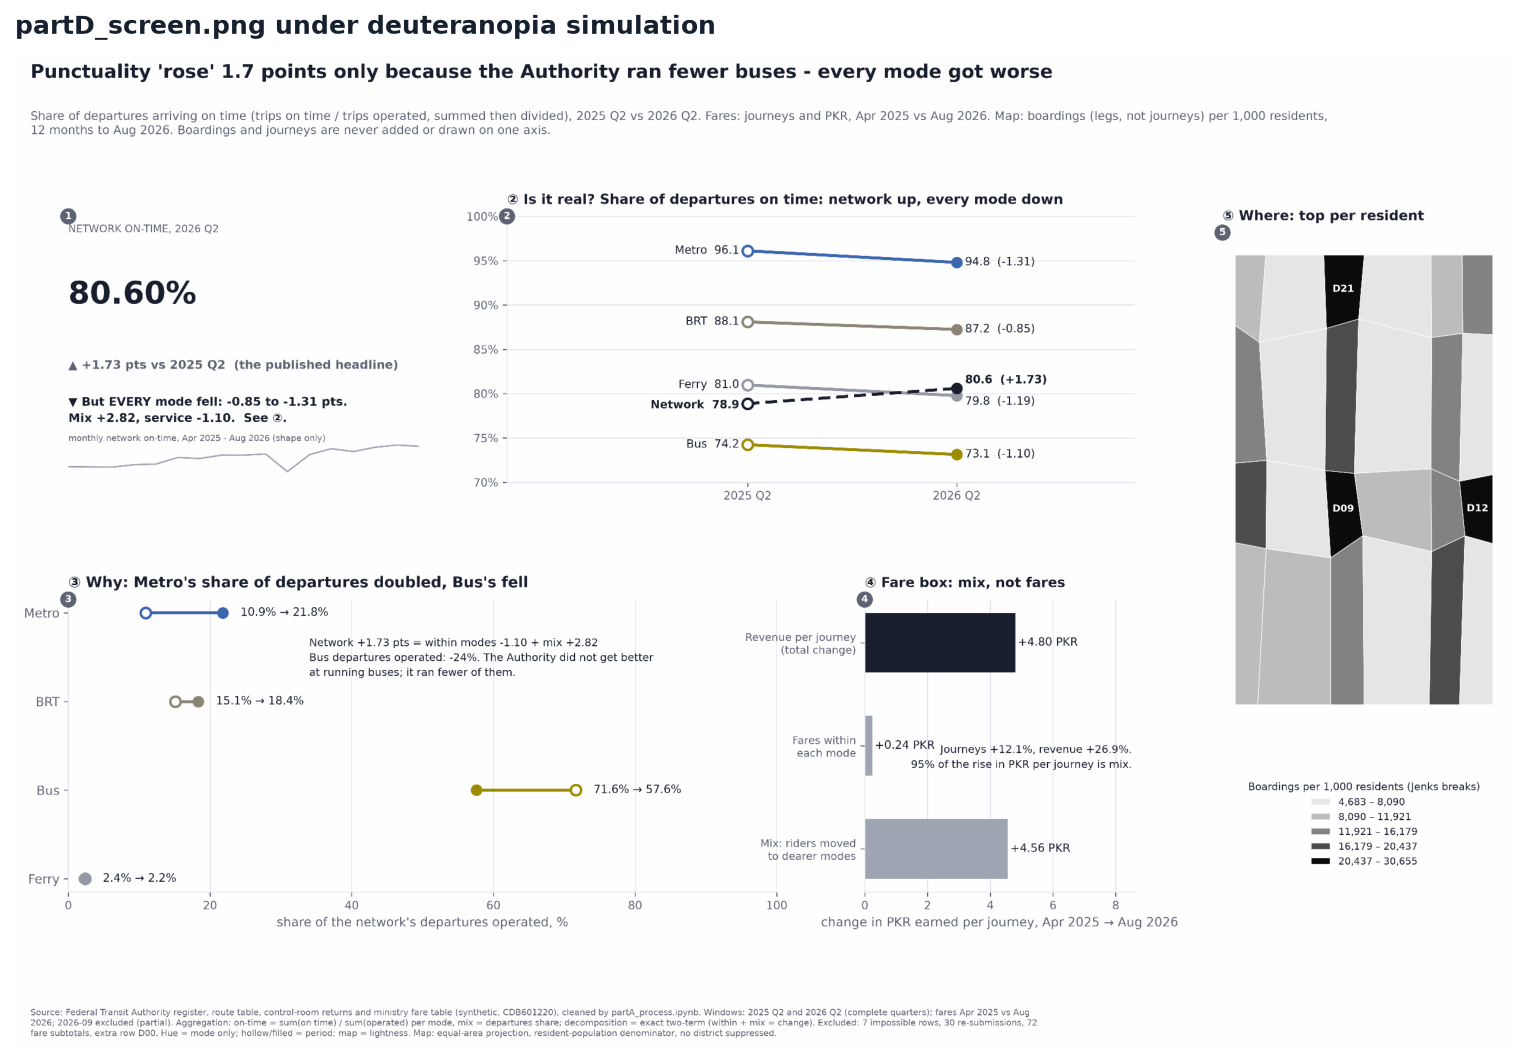

In [6]:
from matplotlib import image as mpimg
img = mpimg.imread("partD_screen.png")[..., :3]
sim = vizlib.simulate_cvd(img[::2, ::2], "deutan")                            # half resolution is plenty for a CVD check
fig2, ax2 = plt.subplots(figsize=(14, 8.6)); ax2.imshow(sim); ax2.axis("off"); ax2.set_title("partD_screen.png under deuteranopia simulation", loc="left")
fig2.savefig("partD_screen_deutan.png", dpi=150, bbox_inches="tight"); plt.show()

## Append the channel plan and the CVD report to the audit (Task A's `partA_audit.txt`)

In [7]:
MARK = "\n\n" + "=" * 78 + "\nTASK D - channel plan and palette check\n" + "=" * 78 + "\n"
txt = Path("partA_audit.txt").read_text(encoding="utf-8")
txt = txt.split(MARK)[0]                                                    # idempotent: replace the section if re-run
sec = ["channel_conflicts(): ok = %s, conflicts = %s" % (cc["ok"], cc["conflicts"]),
       "channels used: " + str(cc["channels_used"]), "redundant (deliberate): " + str(cc["redundant"]), "positional (reported, not flagged): " + str(cc["positional"]), ""]
sec += [f"  {k}: {v}" for k, v in CH_TEXT.items()] + ["", buf.getvalue().rstrip(), ""]
sec += [f"worst pair under {k:7s}: {w[2]} vs {w[3]}  dE {w[4]:.1f} -> {vizlib.verdict(w[4])}" for k, w in worst.items()]
sec += ["Pairs under dE 8 are legal only with a second channel: every mode is ALSO direct-labelled; identity is never colour alone.",
        "The map uses a single-hue grey lightness ramp (no hue), so it cannot collide with the mode hues."]
Path("partA_audit.txt").write_text(txt + MARK + "\n".join(sec) + "\n", encoding="utf-8"); print("appended Task D section to partA_audit.txt")

appended Task D section to partA_audit.txt
